# Weekly Sales Prediction for Women Entrepreneurs

## Mission and problem
My mission is to empower women in Africa, starting in Rwanda, through technology.
This project estimates weekly business sales to support women entrepreneurs
and business advisers with planning.

## Dataset
This project uses baseline survey data covering 3,537 women-owned businesses
in Kenya, from research by David McKenzie and Susana Puerto.

Source: https://doi.org/10.3886/E119063V1

## Scope and limitations
The target is reported sales during the previous week, measured in Kenyan
shillings. This is a sales-estimation prototype, not a future-sales forecast.
Use in Rwanda requires local data and validation. Predictions describe
associations and do not establish causal effects.

In [2]:
from google.colab import files
from pathlib import Path
import pandas as pd

uploaded = files.upload()

Saving kenya_baseline.dta to kenya_baseline.dta


In [3]:
data_files = [
    name for name in uploaded
    if name.lower().endswith(".dta")
]

if len(data_files) != 1:
    raise ValueError("Upload exactly one Stata (.dta) dataset.")

DATA_PATH = Path(data_files[0])

with pd.io.stata.StataReader(
    DATA_PATH,
    convert_categoricals=False,
) as reader:
    raw = reader.read()
    variable_labels = reader.variable_labels()

print(f"Rows: {raw.shape[0]:,}")
print(f"Columns: {raw.shape[1]:,}")

raw.head()

Rows: 3,537
Columns: 959


,respondent_id,rstring,date_dd,date_mm,date_yy,enumerator_code,start_time_hr,start_time_min,business_owner,allow_me_about_10_min,...,b_s1_2_2_2_coded26,b_s1_2_2_2_coded27,b_s1_2_2_2_coded28,b_s1_2_2_2_coded29,b_s1_2_2_2_coded30,b_s1_2_2_2_coded31,b_s1_2_2_2_coded32,b_s1_2_2_2_coded33,b_s1_2_2_2_coded34,b_s1_2_2_2_coded35
0,10060003.0,10060003,17.0,6.0,2013.0,3104.0,15,00,1.0,1.0,...,0,0,0,0,0,0,0,0,0,0
1,10060005.0,10060005,17.0,6.0,2013.0,3104.0,13,10,1.0,1.0,...,0,0,0,0,0,0,0,0,0,0
2,10060006.0,10060006,15.0,6.0,2013.0,3104.0,10,25,NaN,NaN,...,0,0,0,0,0,0,0,0,0,0
3,10060007.0,10060007,15.0,6.0,2013.0,3104.0,14,25,NaN,NaN,...,0,0,0,0,0,0,0,0,0,0
4,10060008.0,10060008,17.0,6.0,2013.0,3104.0,14,10,NaN,NaN,...,0,0,0,0,0,0,0,0,0,0


## Selecting model inputs

The model uses eight inputs: owner age, employee count, weekly working
hours, education level, county, business type, advertising activity,
and written record keeping.

The target is reported weekly sales in Kenyan shillings.
IDs, other sales measurements, and profits are excluded to reduce leakage.
Education is treated as categorical because its codes include qualifications.

In [4]:
column_names = {
    "age": "owner_age",
    "numemployees": "employees",
    "b_s1_5_a": "hours_worked_last_week",
    "b_s1_16": "education_level",
    "b_county": "county",
    "BusinessType": "business_type",
    "b_s9_3": "advertises",
    "b_s9_14": "keeps_written_records",
    "b_s5_6b": "weekly_sales_ksh",
}

data = raw[list(column_names)].rename(columns=column_names).copy()

print(f"Selected inputs: {data.shape[1] - 1}")
print(f"Rows before cleaning: {len(data):,}")

for column in data.columns:
    print(f"\n--- {column} ---")
    print(data[column].value_counts(dropna=False).head(10))

Selected inputs: 8
Rows before cleaning: 3,537

--- owner_age ---
owner_age
27.0    173
35.0    171
31.0    167
33.0    158
29.0    150
28.0    140
40.0    132
26.0    131
45.0    129
41.0    127
Name: count, dtype: int64

--- employees ---
employees
0.0      2828
1.0       473
2.0       160
3.0        55
NaN        20
999.0       1
Name: count, dtype: int64

--- hours_worked_last_week ---
hours_worked_last_week
60    307
72    248
56    243
70    194
54    190
48    183
84    144
66    137
42    131
77     99
Name: count, dtype: int64

--- education_level ---
education_level
8.0     1042
12.0     753
7.0      467
10.0     319
11.0     174
6.0      161
15.0     138
4.0      100
5.0       88
9.0       87
Name: count, dtype: int64

--- county ---
county
KITUI       1190
KISII        842
KAKAMEGA     779
EMBU         713
KISASI         3
               2
KHAYEGA        1
BUTERE         1
KAKA           1
KISIII         1
Name: count, dtype: int64

--- business_type ---
business_type
VEGET

## Data cleaning

Yes/no responses are converted to readable categories. Education codes
are treated as categories rather than years of schooling.

Invalid employee counts and working hours become missing. County names
are standardized; unrecognized locations become missing rather than
being assigned to a guessed county.

Sales of 999 are treated as unknown responses following the survey's
coding convention. Values of 888 are excluded conservatively as ambiguous
responses; this is a cleaning assumption.

Rows with missing or negative sales are removed. Genuine zero sales and
large sales values are retained. Missing inputs will be imputed using
training data only.

In [5]:
import numpy as np

# Rebuild from raw so this cell can safely be rerun.
data = raw[list(column_names)].rename(columns=column_names).copy()

data["employees"] = data["employees"].where(
    data["employees"].between(0, 3)
)

data["hours_worked_last_week"] = data["hours_worked_last_week"].where(
    data["hours_worked_last_week"].between(0, 168)
)

# Education codes 0–18 represent schooling/qualification categories.
data["education_level"] = data["education_level"].map(
    lambda value: f"level_{int(value)}"
    if pd.notna(value) and value in range(19)
    else np.nan
)

for column in ["advertises", "keeps_written_records"]:
    data[column] = data[column].map({1: "yes", 2: "no"})

for column in ["county", "business_type"]:
    data[column] = (
        data[column]
        .astype("string")
        .str.strip()
        .str.upper()
        .replace("", pd.NA)
    )

data["county"] = data["county"].replace({
    "KISIII": "KISII",
    "KAKA": "KAKAMEGA",
})

valid_counties = ["KITUI", "KISII", "KAKAMEGA", "EMBU"]
data["county"] = data["county"].where(
    data["county"].isin(valid_counties)
)

# Clean the target. Do not fill missing sales with an invented value.
data["weekly_sales_ksh"] = data["weekly_sales_ksh"].replace(
    [888, 999], np.nan
)

data = data.loc[
    data["weekly_sales_ksh"].notna()
    & data["weekly_sales_ksh"].ge(0)
].copy()

# Use a consistent missing-value representation.
categorical_features = [
    "education_level",
    "county",
    "business_type",
    "advertises",
    "keeps_written_records",
]

for column in categorical_features:
    data[column] = data[column].astype(object)
    data[column] = data[column].where(data[column].notna(), np.nan)

assert len(data) >= 1000, "Fewer than 1,000 usable rows remain."

print(f"Rows retained: {len(data):,}")
print(f"Rows removed: {len(raw) - len(data):,}")

print("\nMissing values:")
display(data.isna().sum())

print("\nCleaned weekly sales:")
display(data["weekly_sales_ksh"].describe())

Rows retained: 3,065
Rows removed: 472

Missing values:


,0
owner_age,0
employees,17
hours_worked_last_week,0
education_level,2
county,6
business_type,13
advertises,4
keeps_written_records,9
weekly_sales_ksh,0



Cleaned weekly sales:


,weekly_sales_ksh
count,3065.000000
mean,6681.348777
std,14331.209601
min,0.000000
25%,1500.000000
50%,3200.000000
75%,7000.000000
max,461055.000000


## Train/test split

The data is split into 80% training and 20% testing using a fixed random
seed for reproducibility. Exploratory plots use training data only.
Imputation, categorical encoding, and scaling will be fitted on training
data only.

In [6]:
from sklearn.model_selection import train_test_split

numeric_features = [
    "owner_age",
    "employees",
    "hours_worked_last_week",
]

features = numeric_features + categorical_features
target = "weekly_sales_ksh"

X = data[features]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

# Training-only table for exploratory plots.
train_data = X_train.copy()
train_data[target] = y_train

print(f"Training rows: {len(X_train):,}")
print(f"Test rows: {len(X_test):,}")
print(f"Input features: {len(features)}")

Training rows: 2,452
Test rows: 613
Input features: 8


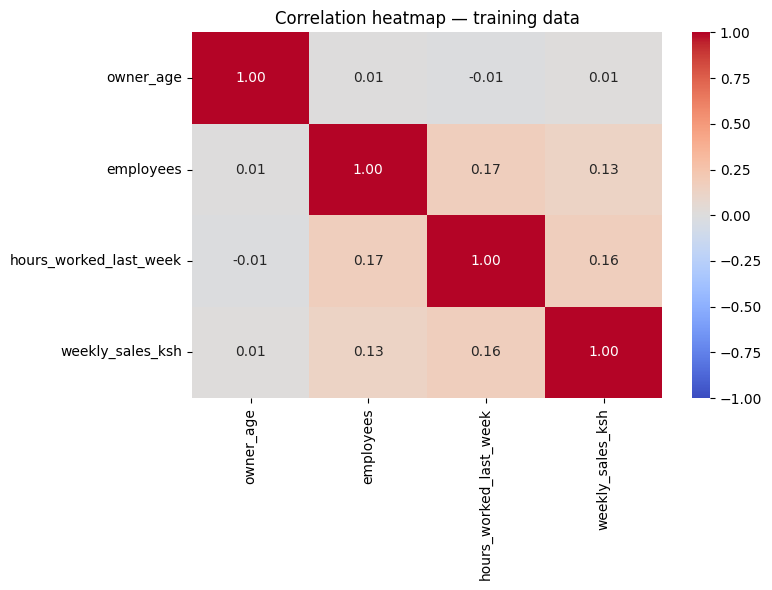

Numeric feature correlations with weekly sales:


,weekly_sales_ksh
hours_worked_last_week,0.164110
employees,0.130679
owner_age,0.010840


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

correlations = train_data[numeric_features + [target]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)
plt.title("Correlation heatmap — training data")
plt.tight_layout()
plt.show()

print("Numeric feature correlations with weekly sales:")
display(
    correlations[target]
    .drop(target)
    .sort_values(key=lambda values: values.abs(), ascending=False)
)

Weekly working hours has the strongest numeric correlation with weekly
sales (0.164), followed by employee count (0.131), while owner age has
almost no linear association (0.011). These weak correlations suggest
that individual numeric inputs may explain little sales variation, so
I will also evaluate categorical inputs and models that capture nonlinear
relationships. Working hours is selected for the one-feature regression
illustration because it has the largest absolute numeric correlation.

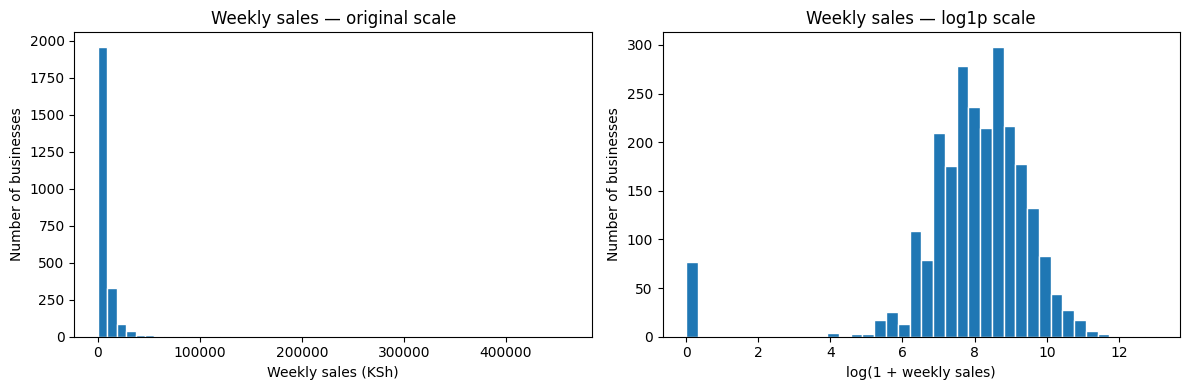

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(y_train, bins=50, edgecolor="white")
axes[0].set_title("Weekly sales — original scale")
axes[0].set_xlabel("Weekly sales (KSh)")
axes[0].set_ylabel("Number of businesses")

axes[1].hist(np.log1p(y_train), bins=40, edgecolor="white")
axes[1].set_title("Weekly sales — log1p scale")
axes[1].set_xlabel("log(1 + weekly sales)")
axes[1].set_ylabel("Number of businesses")

plt.tight_layout()
plt.show()

Most businesses report relatively low weekly sales, while a small number
report much higher values, producing a long right tail. The log1p view
reveals the distribution more clearly while preserving zero-sales cases.
I retain the original sales target and evaluate MSE in KSh², recognizing
that large sales errors will have a strong influence on this metric.

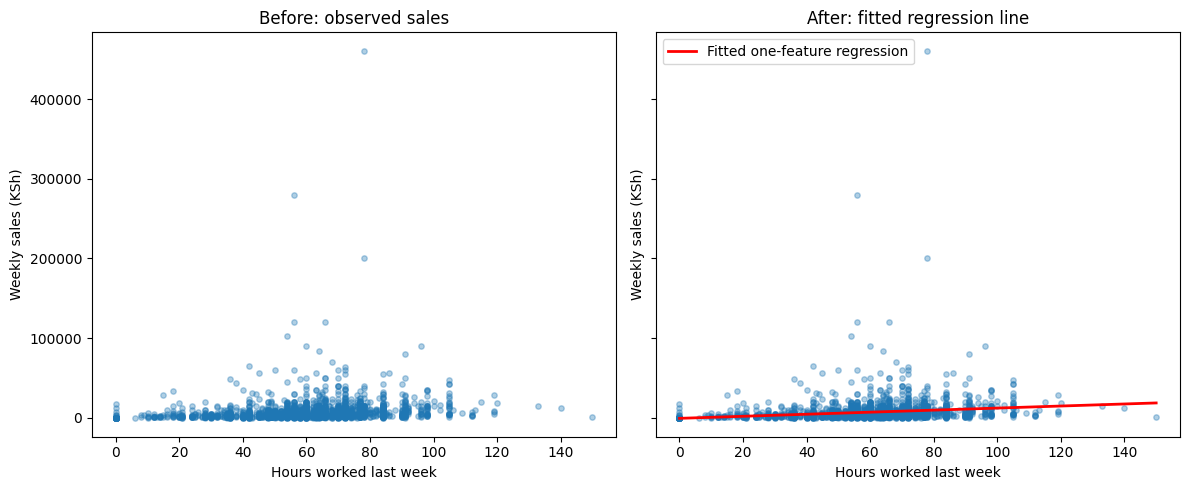

In [9]:
from sklearn.linear_model import LinearRegression

# Select using training data only.
strongest_feature = (
    correlations[target]
    .drop(target)
    .abs()
    .idxmax()
)

plot_data = train_data[[strongest_feature, target]].dropna()

# This one-feature model is only for the illustration.
illustration_model = LinearRegression()
illustration_model.fit(
    plot_data[[strongest_feature]],
    plot_data[target],
)

line_inputs = pd.DataFrame({
    strongest_feature: np.linspace(
        plot_data[strongest_feature].min(),
        plot_data[strongest_feature].max(),
        200,
    )
})
line_predictions = illustration_model.predict(line_inputs)

fig, axes = plt.subplots(
    1, 2, figsize=(12, 5), sharex=True, sharey=True
)

for ax in axes:
    ax.scatter(
        plot_data[strongest_feature],
        plot_data[target],
        alpha=0.35,
        s=15,
    )
    ax.set_xlabel("Hours worked last week")
    ax.set_ylabel("Weekly sales (KSh)")

axes[0].set_title("Before: observed sales")
axes[1].plot(
    line_inputs[strongest_feature],
    line_predictions,
    color="red",
    linewidth=2,
    label="Fitted one-feature regression",
)
axes[1].set_title("After: fitted regression line")
axes[1].legend()

plt.tight_layout()
plt.show()

Before fitting, businesses with similar working hours show widely different
sales, consistent with the weak correlation of 0.164. After fitting, the
regression line slopes upward but fails to capture much of this variation.
I will therefore compare models using all eight inputs; this one-feature
regression is an illustration, not the final prediction model.

## Preprocessing

Numeric inputs are imputed using training-set medians and standardized.
Categorical inputs are imputed using the most frequent training category
and converted to numeric columns using one-hot encoding. The fitted
preprocessor transforms test data without learning from it.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
    )),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

# Fit only on training inputs.
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same fitted transformations to test inputs.
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Test shape:", X_test_processed.shape)
print("All training values finite:",
      np.isfinite(X_train_processed).all())
print("All test values finite:",
      np.isfinite(X_test_processed).all())

Training shape: (2452, 224)
Test shape: (613, 224)
All training values finite: True
All test values finite: True


## Tuning linear regression with gradient descent

SGDRegressor is tuned over three initial learning rates, three L2
regularization strengths, and three epoch counts. Each epoch is trained
using partial_fit.

A validation split is created within the training set. Preprocessing is
fitted on the smaller fitting subset only, and configurations are compared
using validation MSE. The test set is not used to choose hyperparameters.

In [12]:
from sklearn.base import clone
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error

# Split the existing training data for hyperparameter tuning.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
)

# Fresh preprocessing prevents validation leakage.
tuning_preprocessor = clone(preprocessor)

X_fit_processed = tuning_preprocessor.fit_transform(X_fit)
X_val_processed = tuning_preprocessor.transform(X_val)

learning_rates = [0.0001, 0.001, 0.01]
regularization_strengths = [0.0001, 0.001, 0.01]
epoch_options = [50, 150, 300]

tuning_results = []

for eta0 in learning_rates:
    for alpha in regularization_strengths:
        model = SGDRegressor(
            loss="squared_error",
            penalty="l2",
            learning_rate="invscaling",
            eta0=eta0,
            alpha=alpha,
            power_t=0.25,
            random_state=42,
        )

        for epoch in range(1, max(epoch_options) + 1):
            model.partial_fit(X_fit_processed, y_fit)

            if epoch in epoch_options:
                fit_predictions = model.predict(X_fit_processed)
                val_predictions = model.predict(X_val_processed)

                tuning_results.append({
                    "eta0": eta0,
                    "alpha": alpha,
                    "epochs": epoch,
                    "fit_mse": mean_squared_error(
                        y_fit, fit_predictions
                    ),
                    "validation_mse": mean_squared_error(
                        y_val, val_predictions
                    ),
                })

tuning_table = (
    pd.DataFrame(tuning_results)
    .sort_values("validation_mse")
    .reset_index(drop=True)
)

best_sgd_params = {
    "eta0": float(tuning_table.loc[0, "eta0"]),
    "alpha": float(tuning_table.loc[0, "alpha"]),
    "epochs": int(tuning_table.loc[0, "epochs"]),
}

print(f"Configurations evaluated: {len(tuning_table)}")
print("Best SGD parameters:", best_sgd_params)

display(tuning_table.head(10))

Configurations evaluated: 27
Best SGD parameters: {'eta0': 0.001, 'alpha': 0.01, 'epochs': 150}


,eta0,alpha,epochs,fit_mse,validation_mse
0,0.001,0.0100,150,2.354173e+08,6.401378e+07
1,0.001,0.0010,150,2.350592e+08,6.403691e+07
2,0.001,0.0001,150,2.350229e+08,6.404072e+07
3,0.001,0.0100,300,2.333758e+08,6.413120e+07
4,0.001,0.0010,300,2.326849e+08,6.429937e+07
5,0.001,0.0001,300,2.326133e+08,6.432178e+07
6,0.001,0.0001,50,2.382710e+08,6.456357e+07
7,0.001,0.0010,50,2.382846e+08,6.456406e+07
8,0.001,0.0100,50,2.384205e+08,6.457141e+07
9,0.010,0.0100,50,2.293298e+08,6.561578e+07


The lowest validation MSE was obtained with eta0=0.001, alpha=0.01,
and 150 epochs. Increasing this configuration to 300 epochs slightly
increased validation MSE despite reducing fitting MSE, suggesting that
additional training did not improve generalization.

The selected settings are now fixed. The model is trained on the full
training set, recording train and test MSE after each epoch. Test losses
are plotted for the assignment and are not used to change these settings.

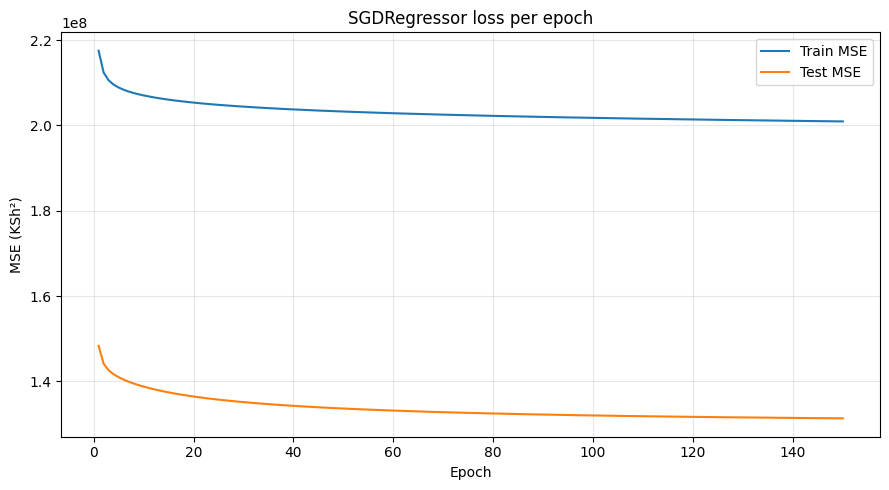

Final train MSE: 200,952,971.96 KSh²
Final test MSE: 131,348,756.35 KSh²
Final test RMSE: 11,460.75 KSh


In [13]:
# Fit fresh preprocessing on the full training set.
preprocessor = clone(preprocessor)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

sgd_model = SGDRegressor(
    loss="squared_error",
    penalty="l2",
    learning_rate="invscaling",
    eta0=best_sgd_params["eta0"],
    alpha=best_sgd_params["alpha"],
    power_t=0.25,
    random_state=42,
)

train_losses = []
test_losses = []

for epoch in range(best_sgd_params["epochs"]):
    sgd_model.partial_fit(X_train_processed, y_train)

    train_losses.append(
        mean_squared_error(
            y_train,
            sgd_model.predict(X_train_processed),
        )
    )
    test_losses.append(
        mean_squared_error(
            y_test,
            sgd_model.predict(X_test_processed),
        )
    )

epochs = np.arange(1, best_sgd_params["epochs"] + 1)

plt.figure(figsize=(9, 5))
plt.plot(epochs, train_losses, label="Train MSE")
plt.plot(epochs, test_losses, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE (KSh²)")
plt.title("SGDRegressor loss per epoch")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Final train MSE: {train_losses[-1]:,.2f} KSh²")
print(f"Final test MSE: {test_losses[-1]:,.2f} KSh²")
print(f"Final test RMSE: {np.sqrt(test_losses[-1]):,.2f} KSh")

Training and test MSE decrease rapidly during the first few epochs,
then improve more slowly. At 150 epochs, training MSE is approximately
200,952,972 KSh² and test MSE is 131,348,756 KSh².

The lower test loss may reflect differences in sales distributions between
the two subsets, particularly extreme values. The test RMSE is approximately
11,461 KSh, which is substantial compared with the dataset's median weekly
sales of 3,200 KSh, so this model requires caution as a planning tool.

## Comparing four regression models

The tuned SGDRegressor is compared with closed-form linear regression,
a decision tree, and a random forest. All models use identical training
and test rows and the same fitted preprocessing.

Tree depth and minimum leaf size are constrained to limit overfitting.
These settings are fixed before evaluating the other three models.
All models are compared using MSE on the original sales scale.

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor

models = {
    "SGDRegressor": sgd_model,
    "LinearRegression": LinearRegression(),
    "DecisionTreeRegressor": DecisionTreeRegressor(
        max_depth=6,
        min_samples_leaf=20,
        random_state=42,
    ),
    "RandomForestRegressor": RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1,
    ),
}

results = []

for name, model in models.items():
    # SGD was already trained using partial_fit.
    if name != "SGDRegressor":
        model.fit(X_train_processed, y_train)

    train_predictions = model.predict(X_train_processed)
    test_predictions = model.predict(X_test_processed)

    results.append({
        "model": name,
        "train_mse": mean_squared_error(
            y_train, train_predictions
        ),
        "test_mse": mean_squared_error(
            y_test, test_predictions
        ),
        "test_rmse_ksh": np.sqrt(
            mean_squared_error(y_test, test_predictions)
        ),
    })

comparison = (
    pd.DataFrame(results)
    .sort_values("test_mse")
    .reset_index(drop=True)
)

display(comparison.round(2))

# A reference baseline: always predict the training-set mean.
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train_processed, y_train)

baseline_mse = mean_squared_error(
    y_test,
    baseline.predict(X_test_processed),
)

best_model_name = comparison.loc[0, "model"]
best_model = models[best_model_name]

print(f"Mean-prediction baseline test MSE: {baseline_mse:,.2f}")
print(f"Lowest-test-MSE model: {best_model_name}")
print(
    f"Selected model test MSE: "
    f"{comparison.loc[0, 'test_mse']:,.2f} KSh²"
)

,model,train_mse,test_mse,test_rmse_ksh
0,SGDRegressor,2.009530e+08,1.313488e+08,11460.75
1,RandomForestRegressor,1.573328e+08,1.315398e+08,11469.08
2,DecisionTreeRegressor,1.951656e+08,1.393207e+08,11803.42
3,LinearRegression,9.689377e+07,1.904371e+08,13799.89


Mean-prediction baseline test MSE: 151,004,292.64
Lowest-test-MSE model: SGDRegressor
Selected model test MSE: 131,348,756.35 KSh²


## Model selection and interpretation

SGDRegressor is selected because it has the lowest test MSE:
131,348,756.35 KSh², with an RMSE of 11,460.75 KSh.
This improves on the mean-prediction baseline MSE of 151,004,292.64 KSh²
by approximately 13%.

Random forest performs almost equally well, so the ranking may change
with a different data split. Closed-form linear regression has much lower
training loss but higher test loss, indicating poorer generalization
on this split.

The weak numeric correlations, highly skewed sales, and numerous encoded
categories make prediction challenging. Regularization may help explain
SGD's performance, while the tree models can capture nonlinear patterns.
These are plausible explanations rather than proven causes.

The selected model's error remains substantial compared with median sales
of 3,200 KSh. Better business measurements, more representative data, and
validation across locations would be needed before practical use.
Selection follows the assignment's lowest-test-MSE rule; an additional
independent dataset would be needed for an unbiased final assessment.

In [15]:
from sklearn.inspection import permutation_importance

# Combine the already-fitted preprocessing and winning model.
# Do not call fit again: that would retrain the selected model.
best_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", best_model),
])

# Check that packaging has not changed predictions.
np.testing.assert_allclose(
    best_pipeline.predict(X_test),
    best_model.predict(X_test_processed),
)

# Training-only exploratory importance:
# shuffle each original input and measure the increase in MSE.
importance_result = permutation_importance(
    best_pipeline,
    X_train,
    y_train,
    scoring="neg_mean_squared_error",
    n_repeats=5,
    random_state=42,
    n_jobs=1,
)

feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "mean_mse_increase": importance_result.importances_mean,
    "std_mse_increase": importance_result.importances_std,
}).sort_values("mean_mse_increase", ascending=False)

display(feature_importance.round(2))

,feature,mean_mse_increase,std_mse_increase
5,business_type,10266862.35,1062702.82
2,hours_worked_last_week,7437288.86,848141.79
1,employees,4984033.92,870283.21
3,education_level,2215944.10,437097.09
7,keeps_written_records,1233744.26,481171.34
4,county,299429.96,94267.04
6,advertises,249986.23,230386.01
0,owner_age,50986.56,104425.64


## Feature importance

Training-set permutation importance ranks business type, weekly working
hours, and employee count highest: shuffling these inputs causes the
largest increases in MSE. Owner age has the smallest estimated importance,
consistent with its weak linear correlation with sales.

These results describe the fitted model on training data, not causal
effects or independently validated importance. All eight inputs are
retained for the final model.

In [16]:
import joblib
import sklearn
import scipy
import sys

MODEL_PATH = Path("best_model.pkl")

# Save the fitted preprocessing and selected model together.
joblib.dump(best_pipeline, MODEL_PATH)

# Verify that saving/loading does not change predictions.
loaded_pipeline = joblib.load(MODEL_PATH)

np.testing.assert_allclose(
    best_pipeline.predict(X_test),
    loaded_pipeline.predict(X_test),
)

print(f"Saved: {MODEL_PATH}")
print(f"File size: {MODEL_PATH.stat().st_size:,} bytes")
print("Reload check passed.")

Saved: best_model.pkl
File size: 11,716 bytes
Reload check passed.


In [17]:
def predict_one_row(row, model_path="best_model.pkl"):
    """Load the saved pipeline and predict sales for one input row."""
    pipeline = joblib.load(model_path)

    if isinstance(row, pd.Series):
        row = row.to_frame().T
    elif isinstance(row, dict):
        row = pd.DataFrame([row])

    if not isinstance(row, pd.DataFrame) or len(row) != 1:
        raise ValueError("Provide exactly one row.")

    required_features = list(pipeline.feature_names_in_)
    return float(pipeline.predict(row[required_features])[0])


example_row = X_test.iloc[[0]]
prediction = predict_one_row(example_row)

display(example_row)
print(f"Predicted weekly sales: {prediction:,.2f} KSh")
print(f"Actual weekly sales: {y_test.iloc[0]:,.2f} KSh")

# Record versions so the local API can match the training environment.
print("\nTraining environment:")
print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("scipy:", scipy.__version__)
print("joblib:", joblib.__version__)

,owner_age,employees,hours_worked_last_week,education_level,county,business_type,advertises,keeps_written_records
1385,44.0,0.0,64.0,level_12,KISII,GRAIN SELLER AND GROCERY,no,no


Predicted weekly sales: 7,436.99 KSh
Actual weekly sales: 2,000.00 KSh

Training environment:
Python: 3.13.18
scikit-learn: 1.6.1
numpy: 2.4.6
pandas: 2.2.3
scipy: 1.16.3
joblib: 1.6.0


In [18]:
files.download("best_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>